# What is Batch Normalization?

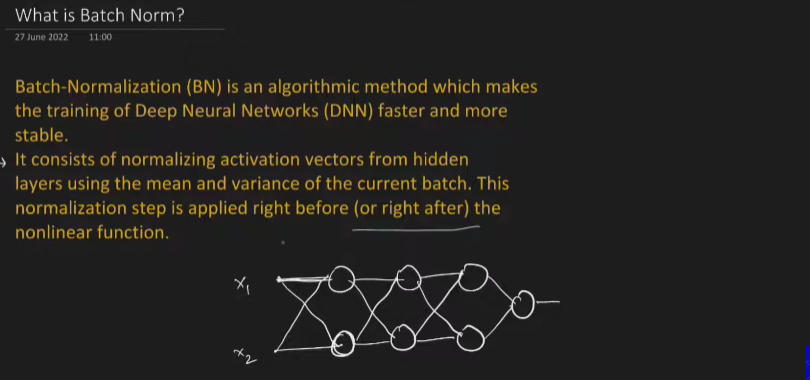

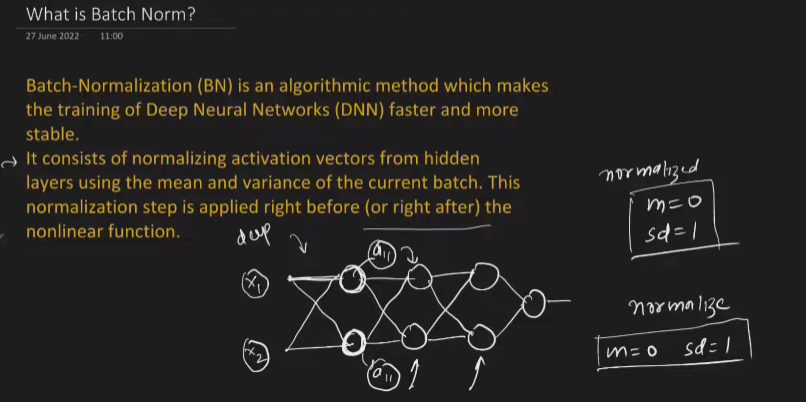

- Similar to how we normalize input features before feeding them into a neural network, **Batch Normalization normalizes the outputs (activations) of each layer** to have a mean of 0 and a standard deviation of 1, helping stabilize training and achieve faster convergence.

# Why use Batch Normalization?

## Reason 1: Contour of loss function

- As we studied earlier in [Data Scaling](../D19-Data-Scaling-In-NN/feature_scaling.ipynb) lecture, that we need to scale the input features before feeding them into a neural network. 

- This is because if we don't scale the input features, then the contour of loss function will be elongated and the gradient descent will take longer to converge.

- However, even if we scale the input features the contour of loss function will form better parabolloid, making convergence faster and stable

- So in batch normalization, we normalize the outputs of each layer to have a mean of 0 and a standard deviation of 1 as well, which helps to stabilize the training process and achieve faster convergence.

## Reason 2: Internal Covariate Shift

### Covariate Shift:

- Covariate Shift occurs when the distribution of input features changes between the training and testing phases. Even if the model fits the training and testing data well, this difference in distributions can affect its generalization to unseen data.

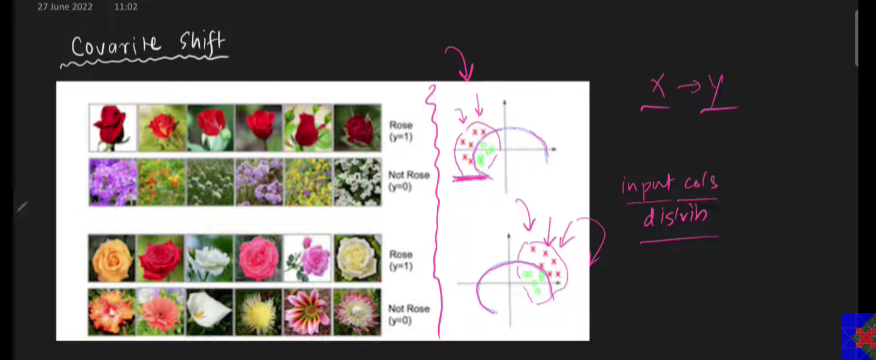

- As shown in the image, the model may perform well on both datasets, but the change in input distribution can still lead to poor performance in real-world scenarios. To address this, we may need to retrain the model using data from the new distribution.

- In the image, while training we trained using red roses. but while testing we tested using different colour of roses. This created the covariate shift problem. 

### Internal Covariate Shift:

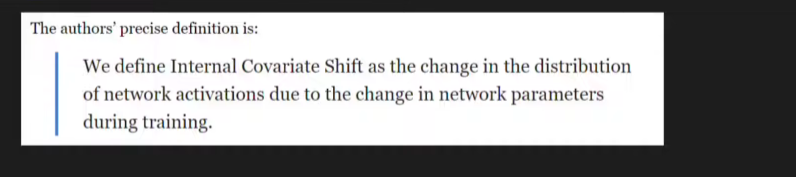

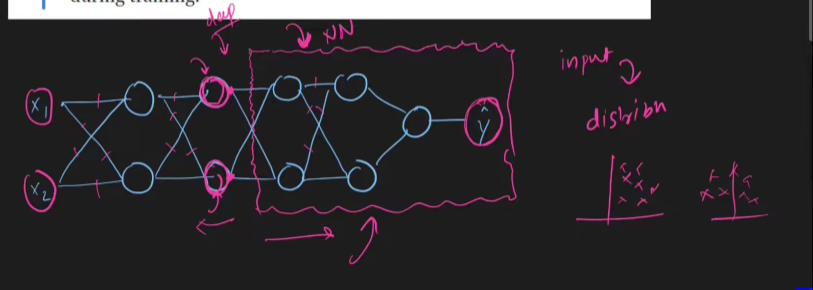

- As shown in the above figure, the input to each layer is the output of the previous layer. During training, as the parameters of previous layers keep updating, their outputs also change. This causes the distribution of inputs to the subsequent layers to keep changing. This phenomenon is called **Internal Covariate Shift**.

- Because of this, the subsequent layers have to continuously adapt to the changing input distributions, which can slow down training and make it harder for the model to converge.

- <text style="color:orange"> Batch normalization helps to mitigate the internal covariate shift by normalizing the inputs to each layer, ensuring that they have a consistent **normal distribution** throughout training. This allows the model to learn more effectively and converge faster.</text>

- If we don't use batch normalization, then we would have to use a **smaller learning rate** and we would have had to do **parameter initialization carefully**. But with batch normalization we no need to worry much about these things. 

# How does Batch Normalization work?

### Things to remember before we start:

1. We apply it with mini-batch gradient descent.
2. It applies in layer by layer basis. Ek time pe ek hi layer pe lagega
2. Also it is optional, jaruri nhi ki saare layer pe lagana padega

### Let's see for a single layer:

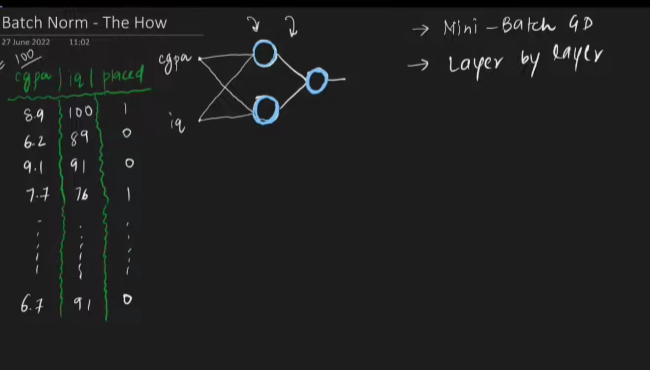

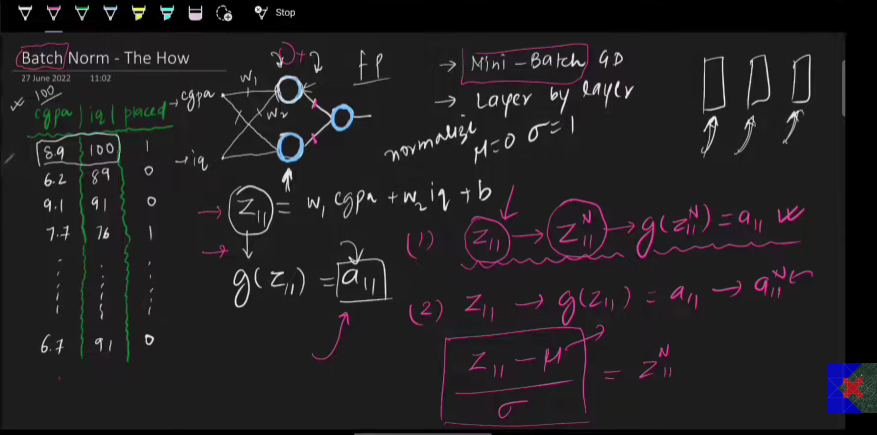

- There are 2 approaches to apply batch normalization as shown in the above figure. But the first approach is more common and widely used. So we will focus on that.

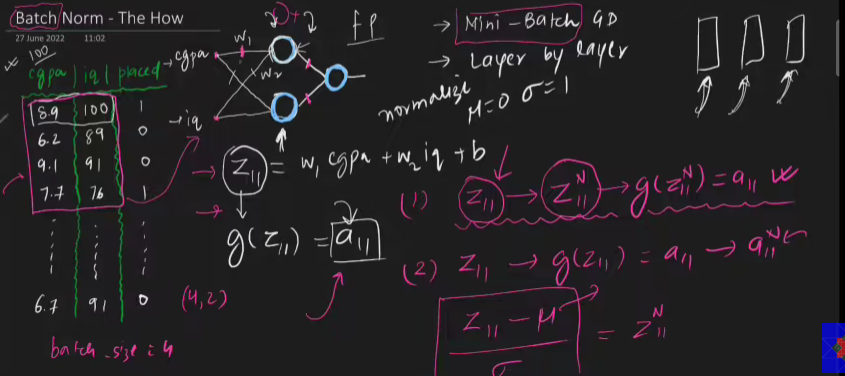

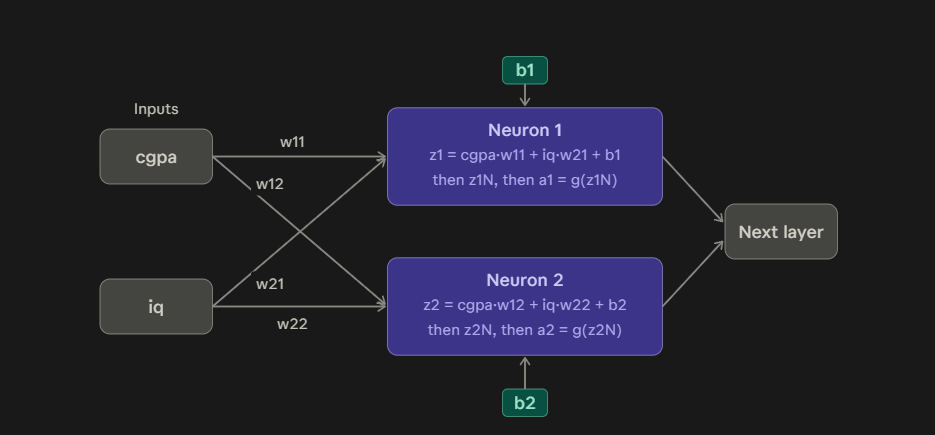



Batch norm is used together with **mini-batch gradient descent**. It is applied **layer by layer**, to the output of each layer, for one mini-batch at a time.

## **The idea in one line**

<mark>Batch normalization = **Normalization** + **Scale and Shift**</mark>

1. **Normalize:** rescale each neuron's values (over the mini-batch) to **mean 0** and **standard deviation 1**.
2. **Scale and shift:** let the network adjust that distribution using two learnable parameters, **$\gamma$** and **$\beta$**.

Then the **activation** is applied.

## **The network we are using**

```mermaid
flowchart LR
  cgpa((cgpa)) -->|w11| N1["Neuron 1<br/>z1 = cgpa·w11 + iq·w21 + b1<br/>z1N = normalize(z1)<br/>z1BN = γ1·z1N + β1<br/>a1 = g(z1BN)"]
  cgpa -->|w12| N2["Neuron 2<br/>z2 = cgpa·w12 + iq·w22 + b2<br/>z2N = normalize(z2)<br/>z2BN = γ2·z2N + β2<br/>a2 = g(z2BN)"]
  iq((iq)) -->|w21| N1
  iq -->|w22| N2
  b1[b1] --> N1
  b2[b2] --> N2
  N1 --> out["Next layer"]
  N2 --> out
```

**Naming used below:**

- $w_{ij}$ is the **weight** from input feature $i$ to neuron $j$.
- $b_j$ is the **bias** of neuron $j$.
- $z_{ij}$ is the value for **sample $i$ at neuron $j$** (index order: sample, then neuron).
- $m$ is the **mini-batch size** (here $m = 4$).

## **Step 0: Take a mini-batch**

Batch size = 4, so we pick 4 samples. Each sample has 2 features (cgpa, iq), so <mark>the input matrix has shape **(4, 2)**: 4 rows (samples) and 2 columns (features).</mark>

$$
X =
\begin{bmatrix}
8.9 & 100 \\
6.2 & 89 \\
9.1 & 91 \\
7.7 & 76
\end{bmatrix}
\quad (4 \times 2)
$$

## **Step 1: Linear step (weights and bias)**

The hidden layer has 2 neurons, so the weights form a **(2, 2)** matrix and the biases form a **(1, 2)** row.

$$
W =
\begin{bmatrix}
w_{11} & w_{12} \\
w_{21} & w_{22}
\end{bmatrix}
\quad (2 \times 2)
\qquad
b =
\begin{bmatrix}
b_1 & b_2
\end{bmatrix}
\quad (1 \times 2)
$$

Multiply and add the bias:

$$
Z = XW + b
\qquad
(4 \times 2)\cdot(2 \times 2) + (1 \times 2) = (4 \times 2)
$$

The bias row is added to every one of the 4 rows (this is called **broadcasting**).

$$
Z =
\begin{bmatrix}
z_{11} & z_{12} \\
z_{21} & z_{22} \\
z_{31} & z_{32} \\
z_{41} & z_{42}
\end{bmatrix}
$$

**How to read it:**

- Each **row** is one **sample**.
- Each **column** is one **neuron**.
- Column 1 holds the 4 values of neuron 1, column 2 holds the 4 values of neuron 2.

For example, sample 1 at neuron 1:

$$
z_{11} = w_{11} \cdot \text{cgpa}_1 + w_{21} \cdot \text{iq}_1 + b_1
$$

<mark>$Z$ is called the **pre-activation** (the value before the activation function is applied).</mark>

## **Step 2: Normalize each column of Z**

<mark>Statistics are computed **per neuron**, that is, down each column over the $m$ samples of the mini-batch.</mark>

**Batch mean** of neuron $j$:

$$
\mu_{B,j} = \frac{1}{m} \sum_{i=1}^{m} z_{ij}
$$

**Batch variance** of neuron $j$:

$$
\sigma_{B,j}^2 = \frac{1}{m} \sum_{i=1}^{m} \left( z_{ij} - \mu_{B,j} \right)^2
$$

**Normalized value:**

$$
z_{ij}^{N} = \frac{z_{ij} - \mu_{B,j}}{\sqrt{\sigma_{B,j}^2 + \epsilon}}
$$

Here $\mu_{B}$ is the mean of the mini-batch, $\sigma_B^2$ is its variance, and $\epsilon$ is a tiny constant (like $10^{-5}$) that only **prevents division by zero**.

<mark>After this step, every column has **mean 0** and **standard deviation 1** ($\mu = 0$, $\sigma = 1$).</mark> The shape does not change:

$$
Z^{N} =
\begin{bmatrix}
z_{11}^{N} & z_{12}^{N} \\
z_{21}^{N} & z_{22}^{N} \\
z_{31}^{N} & z_{32}^{N} \\
z_{41}^{N} & z_{42}^{N}
\end{bmatrix}
\quad (4 \times 2)
$$

### **Small example (one neuron, ignoring $\epsilon$)**

Say column 1 of $Z$ is $[2, 4, 6, 8]$.

$$
\mu_B = 5, \qquad \sigma_B^2 = \frac{9+1+1+9}{4} = 5, \qquad \sigma_B \approx 2.24
$$

$$
Z^{N}_{\text{col 1}} \approx [-1.34,\; -0.45,\; 0.45,\; 1.34]
$$

The new values are **centered at 0** and have **spread 1**.

## **Step 3: Scale and shift**

<mark>Forcing every neuron to mean 0 and standard deviation 1 is not always what the network needs.</mark> Depending on the data, a different distribution may work better. So we give the network two **learnable parameters per neuron**:

- **$\gamma$ (gamma)** is the **scale**.
- **$\beta$ (beta)** is the **shift**.

$$
z_{ij}^{BN} = \gamma_j \cdot z_{ij}^{N} + \beta_j
$$

In matrix form, $\gamma$ and $\beta$ are **(1, 2)** rows, one value per neuron, and they are broadcast over the 4 samples:

$$
\gamma =
\begin{bmatrix}
\gamma_1 & \gamma_2
\end{bmatrix}
\qquad
\beta =
\begin{bmatrix}
\beta_1 & \beta_2
\end{bmatrix}
$$

$$
Z^{BN} = \gamma \odot Z^{N} + \beta
\quad (4 \times 2)
$$

Here $\odot$ means **element-wise multiplication** (each column is multiplied by its own $\gamma_j$).

**Key points about $\gamma$ and $\beta$:**

- <mark>They are **different for each neuron**.</mark>
- <mark>They are **learnable parameters**, just like $w$ and $b$. They are **learnt during training** with gradient descent.</mark>
- They start at **$\gamma = 1$** and **$\beta = 0$**, which means "do nothing" at the beginning.

### **Why scale and shift is a reverse of Step 2**

Step 2 **subtracts** the mean and **divides** by the standard deviation. Step 3 **multiplies** and **adds**. <mark>So it can undo the normalization if the network wants:</mark>

$$
\gamma = \sqrt{\sigma_B^2 + \epsilon}, \qquad \beta = \mu_B
\quad \Rightarrow \quad
z^{BN} = z
$$

This makes batch norm **flexible**. The network can keep the normalized values, or move back to the original distribution, or settle anywhere in between. **Training decides.**

## **Step 4: Activation**

Apply the activation function $g$ to the scaled and shifted values:

$$
A = g(Z^{BN})
\qquad
a_{ij} = g(z_{ij}^{BN})
$$

$$
A =
\begin{bmatrix}
a_{11} & a_{12} \\
a_{21} & a_{22} \\
a_{31} & a_{32} \\
a_{41} & a_{42}
\end{bmatrix}
\quad (4 \times 2)
$$

$A$ is the **output of the hidden layer** and becomes the **input of the next layer**.

## **Whole flow**

For a single value:

$$
z_{11} \;\rightarrow\; z_{11}^{N} \;\rightarrow\; z_{11}^{BN} \;\rightarrow\; g\left(z_{11}^{BN}\right) = a_{11}
$$

For the whole layer:

$$
X \;\xrightarrow{\;XW + b\;}\; Z \;\xrightarrow{\;\text{normalize}\;}\; Z^{N} \;\xrightarrow{\;\gamma \odot Z^{N} + \beta\;}\; Z^{BN} \;\xrightarrow{\;g(\cdot)\;}\; A
$$

## **Two ways to place batch norm**

1. **Before the activation:** $Z \to Z^N \to Z^{BN} \to g(Z^{BN}) = A$. <mark>This is the standard choice and the one used in the lecture.</mark>
2. **After the activation:** $Z \to g(Z) = A \to A^N$.

## **Things to remember**

- <mark>Batch norm works on the layer output $Z$, **not** on the raw input features.</mark>
- <mark>The mean and variance are calculated **per neuron**, over the samples in the **current mini-batch**.</mark>
- <mark>Batch norm = **normalization** + **scale and shift**.</mark>
- $\gamma$ and $\beta$ are **learnable**, one pair per neuron. For our 2-neuron layer that adds **4 extra parameters** ($\gamma_1, \beta_1, \gamma_2, \beta_2$).
- Because the mean is subtracted, the **bias $b$ gets cancelled out**, and $\beta$ takes over its job. So layers followed by batch norm often **drop the bias**.

# Batch Normalization for multi-layer networks

- Keras treats batch normalization as a layer. So we can add it **after** every layer in the network where we want to apply it.

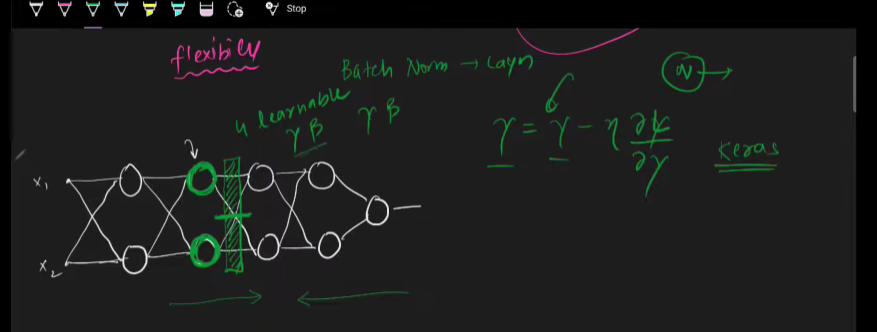

- Every layer will have its own $\gamma$ and $\beta$ parameters, which are learned during training.

- No. of parameters at each  layer = $2 \times$ no. of neurons in that layer.

# **Batch Normalization during Test / Prediction**

## **The problem**

During training, batch norm uses the **mean and variance of the current mini-batch**. At test time this is a problem:

- We do a **forward pass** only, often on a **single sample** (for example, one student's cgpa and iq).
- <mark>There is **no mini-batch** to calculate the mean and variance from.</mark>
- Even with a batch, the output of one sample should not change depending on **which other samples** happen to be in that batch.

## **The solution**

<mark>During training, we keep track of a **running average** of the mean and variance **for each neuron**. At test time we use these stored values instead of mini-batch values.</mark>

The running average is an **Exponentially Weighted Moving Average (EWMA)**.

**Why EWMA?** It gives **more weight to recent mini-batches** and less weight to old ones. Old mini-batches were computed when the weights were still changing a lot, so they are less reliable.

## **Part 1: What we do during training**

For every mini-batch, after computing the batch mean $\mu_{B}$ and batch variance $\sigma_B^2$ of each neuron (Step 2 of batch norm), we also **update the running values**:

$$
\mu_{\text{running}} = \alpha \cdot \mu_{\text{running}} + (1 - \alpha) \cdot \mu_B
$$

$$
\sigma^2_{\text{running}} = \alpha \cdot \sigma^2_{\text{running}} + (1 - \alpha) \cdot \sigma^2_B
$$

**Terms used:**

- $\mu_B$, $\sigma_B^2$ are the mean and variance of the **current mini-batch** (per neuron).
- $\mu_{\text{running}}$, $\sigma^2_{\text{running}}$ are the **stored running values** (per neuron).
- $\alpha$ is the **momentum**, a number close to 1 (commonly 0.9 or 0.99). A larger $\alpha$ means the running value changes slowly and remembers more of the past.
- The starting values are usually $\mu_{\text{running}} = 0$ and $\sigma^2_{\text{running}} = 1$.

<mark>Training itself still **uses the mini-batch mean and variance** for normalization. The running values are only **collected on the side**.</mark>

### **Small example (one neuron)**

Let $\alpha = 0.9$, the old running mean $= 4$, and the current batch mean $\mu_B = 5$:

$$
\mu_{\text{running}} = 0.9 \times 4 + 0.1 \times 5 = 4.1
$$

The running value moves slowly towards the new batch value. The same update is done for the variance.

### **How many values do we store?**

One running mean and one running variance **per neuron**. For our 2-neuron hidden layer:

$$
\mu_{\text{running}} =
\begin{bmatrix}
\mu_1 & \mu_2
\end{bmatrix}
\qquad
\sigma^2_{\text{running}} =
\begin{bmatrix}
\sigma^2_1 & \sigma^2_2
\end{bmatrix}
\qquad (1 \times 2)
$$

<mark>These running values are **not learnable parameters**. Gradient descent does not update them. They are just **statistics collected** while training.</mark>

## **Part 2: What we do during testing**

Now the forward pass for a test input $x$ goes through the same steps, but with **fixed values**.

**Step 1: Linear step (same as before)**

$$
z = xW + b
$$

**Step 2: Normalize using the stored running values**

$$
z^{N} = \frac{z - \mu_{\text{running}}}{\sqrt{\sigma^2_{\text{running}} + \epsilon}}
$$

**Step 3: Scale and shift using the learnt $\gamma$ and $\beta$**

$$
z^{BN} = \gamma \cdot z^{N} + \beta
$$

**Step 4: Activation**

$$
a = g(z^{BN})
$$

<mark>At test time, $\gamma$ and $\beta$ are **not changed**. They are the values **learnt during training**.</mark>

### **Small example (one neuron, ignoring $\epsilon$)**

Say the stored values are $\mu_{\text{running}} = 5$, $\sigma^2_{\text{running}} = 5$, and the learnt parameters are $\gamma = 2$, $\beta = 1$. A test sample gives $z = 6$:

$$
z^{N} = \frac{6 - 5}{\sqrt{5}} \approx 0.45
$$

$$
z^{BN} = 2 \times 0.45 + 1 \approx 1.89
$$

$$
a = g(1.89)
$$

This works for **one single sample**, because nothing depends on a mini-batch anymore.

## **Training vs Testing**

| | **Training** | **Testing** |
|---|---|---|
| Mean and variance come from | the **current mini-batch** | the **stored running averages** (EWMA) |
| Running averages | **updated** at every mini-batch | **not updated** |
| $\gamma$ and $\beta$ | **learnt** (updated by gradient descent) | **fixed** |
| Works on a single sample | no, needs a mini-batch | **yes** |

## **Whole flow**

**Training (each mini-batch):**

$$
Z \;\xrightarrow{\;\mu_B,\;\sigma_B^2\;}\; Z^{N} \;\xrightarrow{\;\gamma,\;\beta\;}\; Z^{BN} \;\xrightarrow{\;g(\cdot)\;}\; A
\qquad
\text{and update } \mu_{\text{running}},\ \sigma^2_{\text{running}}
$$

**Testing:**

$$
z \;\xrightarrow{\;\mu_{\text{running}},\;\sigma^2_{\text{running}}\;}\; z^{N} \;\xrightarrow{\;\gamma,\;\beta\;}\; z^{BN} \;\xrightarrow{\;g(\cdot)\;}\; a
$$

## **Things to remember**

- <mark>Batch norm behaves **differently** in training and in testing.</mark>
- <mark>At test time we use the **EWMA of mean and variance** collected during training, because there is no mini-batch.</mark>
- The running mean and variance are kept **per neuron**.
- They are **statistics, not learnable parameters**. Only $\gamma$ and $\beta$ (along with $w$ and $b$) are learnt.
- Because of this, the prediction for a sample is **independent of other samples**.
- In frameworks like PyTorch and Keras, this is why you switch the model to **train mode** and **eval mode** (`model.train()` and `model.eval()`).

# **Advantages of Batch Normalization**

## **1. Makes training more stable**

<mark>Batch norm keeps the inputs of every layer in a steady range, so training is **less sensitive to hyperparameters**.</mark>

- We get a **wide range of workable values** for hyperparameters like the **learning rate** and **weight initialization**.
- Hyperparameter tuning becomes **easier**, because many more settings give good results.
- Activations are less likely to **blow up** or **die out** as they pass through many layers.

## **2. Makes training faster**

<mark>Because training is stable, we can use a **higher learning rate**, and the network **converges in fewer epochs**.</mark>

- Without batch norm, a high learning rate can make the loss diverge.
- With batch norm, bigger steps are safe, so we reach a good solution sooner.

## **3. Acts as a mild regularizer**

<mark>Batch norm adds a little **noise** to the hidden layer outputs, which can **reduce overfitting**.</mark>

- The mean and variance come from the **current mini-batch**, so the same sample is normalized slightly differently depending on which other samples are in its batch.
- This small randomness works like a light regularization effect. It is **weaker with larger batch sizes**.
- It is **not strong regularization**. If the network still overfits, we should **also use dropout or L2 regularization**.

## **4. Reduces the dependence on careful weight initialization**

<mark>Batch norm keeps each layer's outputs at a consistent scale, so a **poor weight initialization matters much less**.</mark>

- We can use a **wider range of initializations** and still get good results.
- Normalization makes the **contours of the loss function rounder and more bowl-shaped** (closer to a paraboloid) instead of long and narrow.
- On such a surface, **gradient descent takes a more direct path** to the minimum, so it converges **faster and more steadily**.
- So we do not have to worry much about the choice of initial weights.

## **Quick summary**

| **Advantage** | **Why it happens** |
|---|---|
| **More stable training** | layer inputs stay in a steady range |
| **Faster training** | higher learning rates are safe |
| **Mild regularization** | mini-batch statistics add noise |
| **Less sensitive to initialization** | outputs stay scaled, loss contours become rounder |

# Keras Implementation

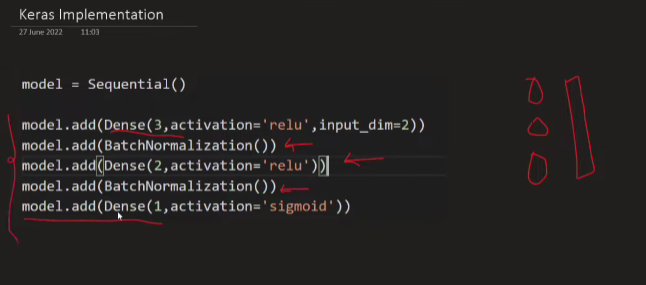

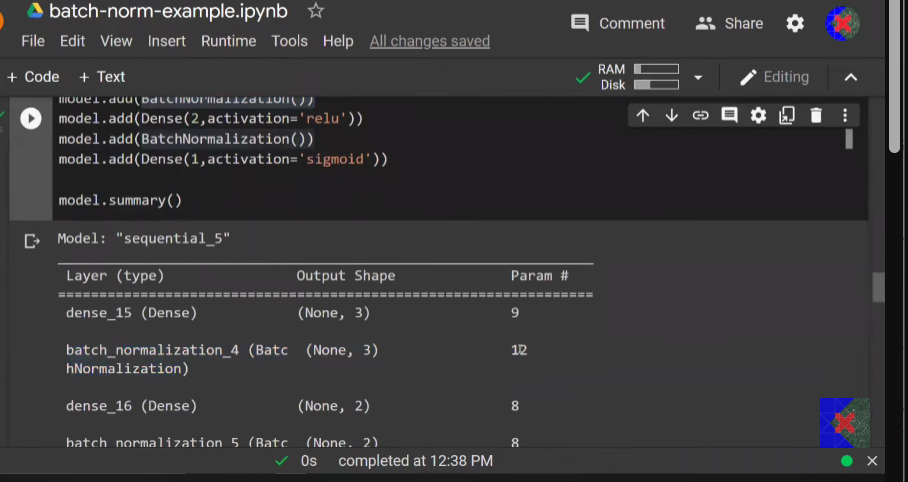

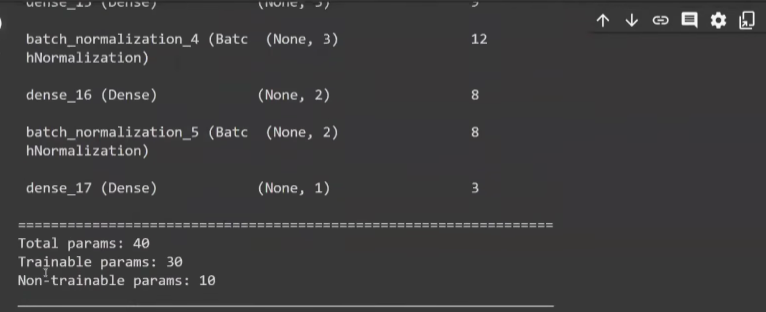

| **Parameter** | **Per neuron** | **Type** | **Role** |
|---|---|---|---|
| $\gamma$ (scale) | 1 | trainable | scales the normalized value |
| $\beta$ (shift) | 1 | trainable | shifts the normalized value |
| moving mean | 1 | non-trainable | EWMA of batch mean, used at test time |
| moving variance | 1 | non-trainable | EWMA of batch variance, used at test time |

**Total per batch norm layer = 4 × number of neurons** (e.g. 3 neurons gives 12: 6 trainable and 6 non-trainable).